In [1]:
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageStat
from tqdm import tqdm

In [8]:
import os
import pathlib
from pathlib import Path

In [9]:
def borrar_poligonos(carpeta, borrar=False):
    carpeta = Path(carpeta)
    labels_dir, images_dir = carpeta / 'labels', carpeta / 'images'

    con_poligono = []
    for txt in labels_dir.glob('*.txt'):
        with open(txt, 'r') as f:
            # MÁS DE 5 VALORES EN UNA LÍNEA = POLÍGONO
            if any(len(l.split()) > 5 for l in f if l.strip()):
                con_poligono.append(txt.stem)

    print(f"{len(con_poligono)} fotos con polígonos en {carpeta.name}")

    if borrar:
        for stem in con_poligono:
            (labels_dir / f"{stem}.txt").unlink()
            # LA IMAGEN PUEDE SER .jpg, .jpeg O .png: SE BUSCA POR NOMBRE
            for img in images_dir.glob(f"{stem}.*"):
                img.unlink()

    return con_poligono

In [12]:
#borrar_poligonos('../data/external/cats_ft', borrar=True)
#borrar_poligonos('../data/external/cats_breeds', borrar=True)
#borrar_poligonos('../data/external/cats_val', borrar=True)

In [13]:
def list_files(path, dict_images=None):
    if dict_images is None:
        dict_images = {
            "file_path": [],
            "dir_name": [], 
            "file_name": [],
            "format": [],
            "resolution": [],
            "ratio": [],
            "mode": [],
            "file_size_mb": [],
            "brightness": []
        }

    base_path = pathlib.Path(path)

    for entry in os.scandir(base_path): 
        entry_path = pathlib.Path(entry.path)

        if entry.is_file():
            if not entry.name.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue
            
            actual_dir = entry_path.parent.name.split('_')[0]
            file_name = entry_path.stem
            file_size = entry.stat().st_size

            try:
                with Image.open(entry.path) as img:
                    img_width, img_height = img.size
                    if img_height == 0:
                        continue

                    stat = ImageStat.Stat(img.convert("L"))
                    img_brightness = round(
                        stat.mean[0], 2
                    )

                    img_format, img_mode, img_resolution, img_ratio = img.format, img.mode, img_width*img_height, round(img_width/img_height, 2)

                    dict_images["file_path"].append(entry_path.as_posix())
                    dict_images["dir_name"].append(actual_dir)
                    dict_images["file_name"].append(file_name)
                    dict_images["format"].append(img_format)
                    dict_images["resolution"].append(img_resolution)
                    dict_images["ratio"].append(img_ratio)
                    dict_images["mode"].append(img_mode)
                    dict_images["file_size_mb"].append(file_size / (1024**2))
                    dict_images["brightness"].append(img_brightness)

            except Exception as e:
                continue

        elif entry.is_dir():
            dict_images = list_files(entry_path, dict_images)

    return dict_images

In [66]:
def agregar_labels(df, labels_dir, nombres=None):
    labels_dir = Path(labels_dir)
    filas = []

    for nombre in df['file_name']:
        txt = labels_dir / f"{nombre}.txt"
        lineas = [l.split() for l in open(txt) if l.strip()] if txt.exists() else []

        if len(lineas) != 1:          # 0 O 2+ CAJAS: SE DESCARTA
            continue

        c, cx, cy, w, h = lineas[0]
        fila = {'file_name': nombre, 'clase': int(c),
                'cx': float(cx), 'cy': float(cy), 'w': float(w), 'h': float(h)}

        if nombres is not None:       # SOLO SI SE PASA LA LISTA SE AGREGA LA RAZA
            fila['raza'] = nombres[int(c)]

        filas.append(fila)

    return df.merge(pd.DataFrame(filas), on='file_name')

**ANALISIS CATS BREEDS**

In [50]:
directory_cat_breeds = '../data/external/cats_breeds/images'
dict_images_cat_breeds = list_files(directory_cat_breeds)
df_images_cat_breeds = pd.DataFrame(dict_images_cat_breeds)

In [68]:
cat_names = ['Abyssianian', 'American Curl', 'American Short Hair', 
            'American Wirehair', 'Balinese', 'Bengal', 'Birman', 
            'Bombay', 'British Shorthair', 'Burmese', 'Burmilla', 
            'Calico', 'Canadian Hairless', 'Chartreux', 'Cornish Rex', 
            'Cymric', 'Devon Rex', 'Dilute Tortoiseshell', 'Domestic Long Hair', 
            'Domestic Medium Hair', 'Domestic Short Hair', 'Egyptian Mau', 
            'Exotic Shorthair', 'Extra-Toe', 'Havana', 'Himalayan', 
            'Japanese Bobtail', 'Javanese', 'Korat', 'Laperm', 'Maine Coon', 
            'Manx', 'Munchkin', 'Norwegian Forest Cat', 'Ocicat', 'Oriental Long Hair', 
            'Oriental Short Hair', 'Oriental Tabby', 'Persian', 'Pixiebob', 'Ragamuffin', 
            'Ragdoll', 'Russian Blue', 'Scottish Fold', 'Selkirk Rex', 'Siamese', 'Siberian', 
            'Silver', 'Singapura', 'Snowshoe', 'Somali', 'Sphynx', 'Tabby', 'Turkish Angora', 'Turkish Van']

In [70]:
df_images_cat_breeds_boxes = agregar_labels(
    df_images_cat_breeds,
    '../data/external/cats_breeds/labels',
    cat_names)

In [71]:
df_images_cat_breeds_boxes.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness,clase,cx,cy,w,h,raza
0,../data/external/cats_breeds/images/00a80980-a...,images,00a80980-a874-48ad-b569-6ca771a71f85_jpeg_jpg....,JPEG,409600,1.0,RGB,0.036536,138.51,44,0.341406,0.482031,0.630469,0.744531,Selkirk Rex
1,../data/external/cats_breeds/images/10895463_9...,images,10895463_920_jpg.rf.7da5102e26e93e0c2f71bf4976...,JPEG,409600,1.0,RGB,0.035977,151.11,4,0.531250,0.457031,0.937500,0.720313,Balinese
2,../data/external/cats_breeds/images/10_jpg.rf....,images,10_jpg.rf.c96cd5eedd0fcb31982a9146ed197813,JPEG,409600,1.0,RGB,0.033439,154.07,0,0.481250,0.603906,0.860938,0.564844,Abyssianian
3,../data/external/cats_breeds/images/11636491_8...,images,11636491_897_jpg.rf.070085395d8daabfec512bf90c...,JPEG,409600,1.0,RGB,0.044143,133.10,6,0.516406,0.511719,0.598437,0.976562,Birman
4,../data/external/cats_breeds/images/11981930_3...,images,11981930_3419_jpg.rf.0946de1cdff96dd061a22cd53...,JPEG,409600,1.0,RGB,0.028156,117.34,33,0.500000,0.500000,1.000000,1.000000,Norwegian Forest Cat


In [72]:
df_images_cat_breeds_boxes.to_csv(
    '../data/processed/detecction/analisis_cat_breeds.csv',
    index=False
)

**EDA CAT BREEDS**

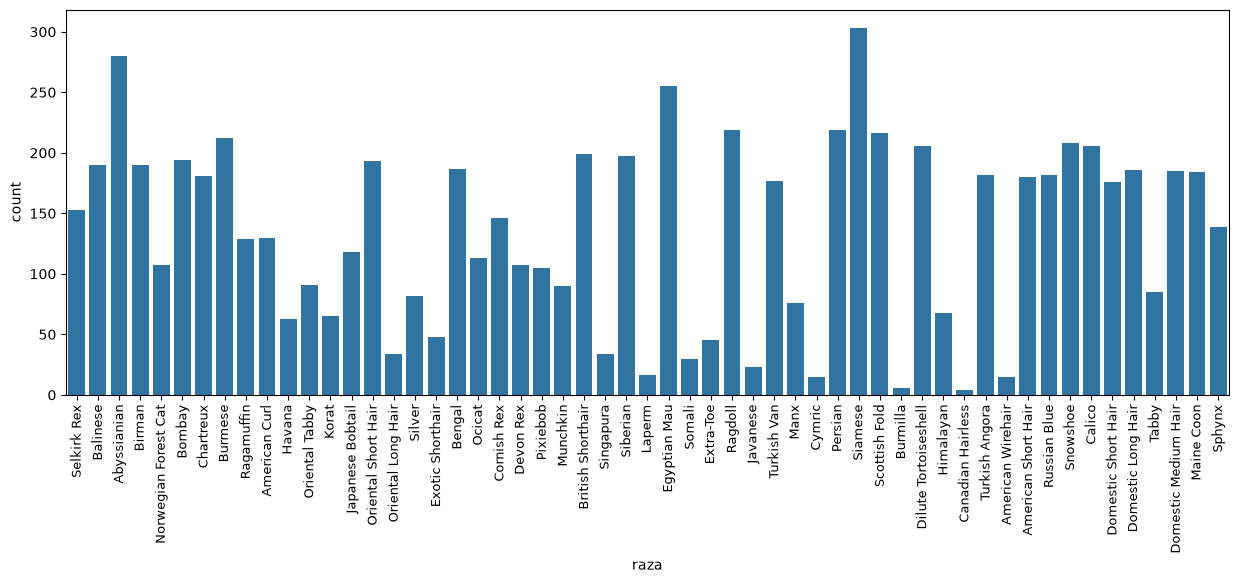

In [89]:
plt.figure(figsize=(15, 5))
sns.countplot(
    data=df_images_cat_breeds_boxes,
    x='raza')
plt.xticks(rotation=90, fontsize=9)
plt.show()

**ANALISIS MUESTRA 300**

In [22]:
directory_muestra_300 = '../data/external/muestra_300/images'
dict_images_muestra_300 = list_files(directory_muestra_300)
df_images_muestra_300 = pd.DataFrame(dict_images_muestra_300)

In [73]:
df_images_muestra_300_boxes = agregar_labels(
    df_images_muestra_300,
    '../data/external/muestra_300/labels')

In [74]:
df_images_muestra_300_boxes.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness,clase,cx,cy,w,h
0,../data/external/muestra_300/images/CAT_00_000...,images,CAT_00_00000001_008,JPEG,187500,1.33,RGB,0.448037,122.72,15,0.745361,0.685567,0.310309,0.421993
1,../data/external/muestra_300/images/CAT_00_000...,images,CAT_00_00000002_008,JPEG,187500,0.75,RGB,0.348036,53.47,15,0.532877,0.504110,0.900457,0.975342
2,../data/external/muestra_300/images/CAT_00_000...,images,CAT_00_00000004_008,JPEG,200000,0.80,RGB,0.348036,87.05,15,0.547089,0.445890,0.715753,0.683562
3,../data/external/muestra_300/images/CAT_00_000...,images,CAT_00_00000004_023,JPEG,224000,1.12,RGB,0.348036,111.67,15,0.490184,0.497097,0.980368,0.983238
4,../data/external/muestra_300/images/CAT_00_000...,images,CAT_00_00000006_029,JPEG,200000,1.25,RGB,0.071042,79.02,15,0.512088,0.416896,0.651648,0.664835


In [75]:
df_images_muestra_300_boxes.to_csv(
    '../data/processed/detecction/analisis_muestra_300.csv',
    index=False
)